[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Tnecniv-Teikram/NSA-hyperspectral-course-2026/blob/main/15_classification_classical.ipynb)

*Running in Colab? Run the setup cell below first — it clones the course and installs what this notebook needs. Running locally? It does nothing.*

# 🗺️ Classification Approaches for Hyperspectral Data
### Space Academy 2026 · Hyperspectral course · Week 2 — Classification approaches for hyperspectral data (Lecture + Practical)

Classification assigns every pixel to one class of a legend — *mangrove, cropland, water…* It is the most common
product made from Earth-observation data, and hyperspectral data make it both **easier** (hundreds of bands describe
each material in detail) and **harder**: bands are highly correlated, labelled samples are scarce compared with the
number of features (the *Hughes phenomenon*: with a fixed number of training samples, accuracy can drop as you add
features), and at 30 m most pixels are mixtures.

In this notebook we map the mangrove coast of **Jiquilisco Bay, El Salvador** with unsupervised and supervised
classifiers, using the ESA WorldCover map as (imperfect) reference labels.

**What you will learn**
- Where training labels come from, and why "pure" pixels and a **spatially separated** train/test split matter
- Unsupervised classification (k-means, Gaussian mixtures) and how to link clusters to classes
- Supervised classification with LDA, Random Forest and an RBF Support Vector Machine
- Which wavelengths a Random Forest relies on
- How much the full spectrum helps compared with simulated Sentinel-2 bands or a few indices — measured honestly
- How label noise (WorldCover 2021 vs a 2025 image, 10 m → 30 m) affects training *and* evaluation
- How to export a classification as a Cloud-Optimised GeoTIFF

**Prerequisites:** `11_preprocessing`, `13_feature_extraction_dim_reduction` (PCA), `14_material_discrimination_target_detection` (SAM).
Rigorous accuracy assessment follows in `21_validation_accuracy_assessment`; deep learning in `20_geoai_deep_learning`.

**Data**
- Tanager scene `20250223_165546_32_4001` — Usulután, El Salvador, 23 Feb 2025 (`hu.get_scene()` uses the local
  HDF5 or downloads ~1 GB from Planet's STAC catalogue).
- ESA WorldCover 2021 (10 m), aggregated to the Tanager 30 m grid: `data/labels/…_worldcover2021_30m.tif`
  (created with `hu.make_worldcover_labels`).

In [ ]:
# --- Setup: works both in Google Colab and in a local environment --------------------
# In Colab this clones the course repository, installs the geospatial packages that Colab
# does not ship, and moves into the course folder so the notebook finds hsi_utils and data/.
# Locally it does nothing at all — your own environment is already active.
import os
import pathlib
import subprocess
import sys

REPO = "Tnecniv-Teikram/NSA-hyperspectral-course-2026"          # change with: python tools/set_repo_url.py <owner>/<repo>

if "google.colab" in sys.modules:
    course = pathlib.Path("/content/hyperspectral-course")
    if not course.exists():
        subprocess.run(["git", "clone", "--depth", "1", "-q",
                        f"https://github.com/{REPO}.git", str(course)], check=True)
    os.chdir(course)
    sys.path.insert(0, str(course))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "h5py", "rasterio", "rioxarray", "xarray", "geopandas"], check=True)
    print("Colab ready — course at", course)
else:
    print("Local environment:", sys.executable.split("/")[-3])


## 0. You have done this before — in ENVI, SNAP or QGIS

If you have ever digitised training polygons and run a maximum-likelihood classification, you have already done
supervised classification. The workflow is the same; only the vocabulary and the tooling change.

| What you call it in desktop GIS | What it is called here | Note |
|---|---|---|
| Digitising ROIs / training polygons | **Labelling**, producing `y` | We use ESA WorldCover as ready-made labels (§1) |
| The pixel values under a ROI | **Features**, the matrix `X` | One row per pixel, one column per band — 352 columns here |
| Maximum likelihood / Mahalanobis | **LDA**, **GMM** | Same Gaussian assumption, different name |
| Parallelepiped / minimum distance | A **threshold classifier** | We compare against one in §7 |
| "Train the classifier" | `model.fit(X, y)` | Identical idea |
| Applying the signature to the scene | `model.predict(X)` | §4.1 |
| Accuracy assessment with ground-truth points | **Test set** evaluation | With one crucial change, below |
| Commission / omission error | **User's / producer's accuracy** (precision / recall) | Same numbers, different words |
| Kappa | *Reported, but not relied on* | See notebook 21 — current good practice has moved on from kappa |

**The one habit worth changing.** In desktop software it is normal to draw training and validation polygons across
the same scene, often side by side. With 30 m pixels that are strongly spatially autocorrelated, this inflates your
accuracy — neighbouring pixels are nearly the same measurement, so the model is partly being tested on what it was
trained on. Section 2 therefore splits the scene into **spatially separated blocks**. Expect lower, more honest
numbers than you are used to seeing.

**The one thing that genuinely breaks.** With 10 bands you could feed everything to the classifier. With 352
correlated bands and a few hundred training pixels, accuracy *falls* as you add bands — the Hughes phenomenon of
notebook 13. That is why PCA, MNF and band selection exist, and why §5 asks whether all this spectral detail is
even helping.

In [1]:
# On Google Colab: upload hsi_utils.py next to this notebook and uncomment:
# %pip install -q h5py numpy scipy matplotlib scikit-learn pandas rasterio xarray rioxarray requests
import time
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import linear_sum_assignment
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import hsi_utils as hu

plt.rcParams["figure.dpi"] = 90
rng = np.random.default_rng(42)

## 1. Image and reference labels

We work on a 400 × 440 pixel window (12 × 13 km) that contains all the main land covers of the bay.

In [2]:
SCENE = "20250223_165546_32_4001"
scene = hu.get_scene(SCENE)
W = (80, 480, 60, 500)                      # (row_start, row_stop, col_start, col_stop)
ext = (W[2], W[3], W[1], W[0])

t0 = time.time()
cube, wl = scene.read_cube(W)
print(f"cube {cube.shape} read in {time.time() - t0:.1f} s  ({cube.nbytes / 1e6:.0f} MB)")

wc, purity = hu.load_labels(SCENE, W)       # WorldCover class code and purity (0–9) per 30 m pixel
X_all, valid = hu.cube_to_pixels(cube)      # (pixels, bands) of complete spectra + 2-D mask
print(f"{X_all.shape[0]} valid pixels, {X_all.shape[1]} bands")

cube (352, 400, 440) read in 1.3 s  (248 MB)


173721 valid pixels, 352 bands


**Purity.** Each 30 m Tanager pixel covers nine 10 m WorldCover cells. `purity` counts how many of the nine agree
with the majority class: 9/9 means the pixel is (according to WorldCover) homogeneous. Training on pure pixels gives
clean spectra; the price is that edges and mixtures are never seen during training.

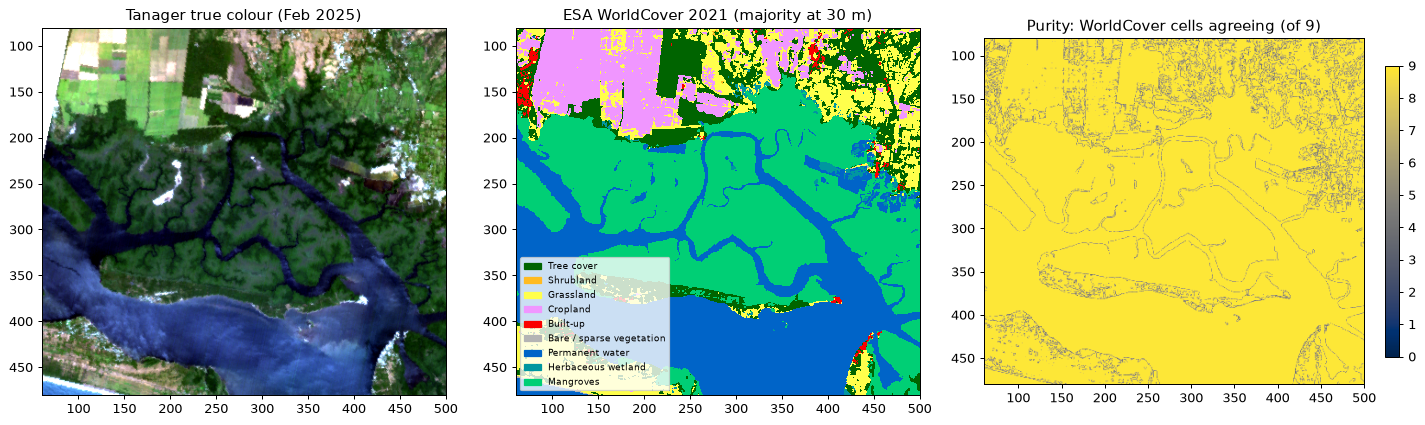

,class,all pixels,pure (9/9)
10,Tree cover,20231,14900
20,Shrubland,32,7
30,Grassland,21306,15037
40,Cropland,16551,13731
50,Built-up,911,359
60,Bare / sparse vegetation,163,57
80,Permanent water,50898,48333
90,Herbaceous wetland,1294,603
95,Mangroves,62335,59169


In [3]:
cmap_wc, norm_wc, handles_wc = hu.label_cmap(np.unique(wc[wc > 0]))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
axes[0].imshow(hu.rgb_from_cube(cube, wl), extent=ext); axes[0].set_title("Tanager true colour (Feb 2025)")
axes[1].imshow(np.where(wc > 0, wc, np.nan), cmap=cmap_wc, norm=norm_wc, interpolation="nearest", extent=ext)
axes[1].set_title("ESA WorldCover 2021 (majority at 30 m)")
axes[1].legend(handles=handles_wc, fontsize=7, loc="lower left")
im = axes[2].imshow(purity, cmap="cividis", vmin=0, vmax=9, extent=ext)
axes[2].set_title("Purity: WorldCover cells agreeing (of 9)"); plt.colorbar(im, ax=axes[2], fraction=0.035)
plt.tight_layout(); plt.show()

counts = pd.DataFrame({
    "class": [hu.WORLDCOVER_CLASSES[c][0] for c in sorted(hu.WORLDCOVER_CLASSES)],
    "all pixels": [int(((wc == c) & valid).sum()) for c in sorted(hu.WORLDCOVER_CLASSES)],
    "pure (9/9)": [int(((wc == c) & valid & (purity == 9)).sum()) for c in sorted(hu.WORLDCOVER_CLASSES)],
}, index=sorted(hu.WORLDCOVER_CLASSES))
counts[counts["all pixels"] > 0]

We keep the five classes with thousands of pure pixels. Built-up, bare and herbaceous wetland have too few pure
30 m pixels (and a "pure" built-up pixel at 30 m is still a mixture of roofs, roads and trees) — in a real project
you would collect extra samples for them or merge them into an *other* class.

In [4]:
CLASSES = [95, 10, 30, 40, 80]
NAMES = [hu.WORLDCOVER_CLASSES[c][0] for c in CLASSES]
COLORS = [hu.WORLDCOVER_CLASSES[c][1] for c in CLASSES]
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
cmap5 = ListedColormap(COLORS); cmap5.set_bad("white")
norm5 = BoundaryNorm(np.arange(-0.5, len(CLASSES)), cmap5.N)
legend5 = [Patch(color=c, label=n) for c, n in zip(COLORS, NAMES)]

label_idx = np.full(wc.shape, -1)              # class index 0..4, −1 = not used
for i, c in enumerate(CLASSES):
    label_idx[wc == c] = i
print(dict(zip(NAMES, [int(((label_idx == i) & (purity == 9) & valid).sum()) for i in range(5)])))

{'Mangroves': 59169, 'Tree cover': 14900, 'Grassland': 15037, 'Cropland': 13731, 'Permanent water': 48333}


## 2. A spatially separated train/test split

Neighbouring pixels are almost identical (*spatial autocorrelation*). If training and test pixels are drawn at
random from the same fields, the classifier is tested on near-copies of its training data and accuracy is inflated.
We therefore divide the window into **40 × 40 pixel blocks (1.2 km)** and send whole blocks to either training or
testing (one third of the blocks are test blocks).

From the training blocks we draw up to **1 500 pure pixels per class** (a balanced sample); from the test blocks up to
3 000 pure pixels per class.

training pixels per class: [1500 1500 1500 1500 1500]  test pixels per class: [3000 3000 3000 2549 3000]


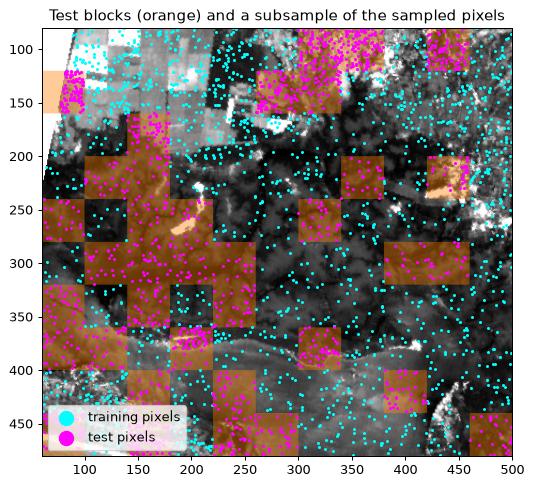

In [5]:
BLOCK = 40
rows_i, cols_i = np.indices(wc.shape)
block_id = (rows_i // BLOCK) * 1000 + cols_i // BLOCK
blocks = np.unique(block_id)
test_blocks = rng.choice(blocks, size=len(blocks) // 3, replace=False)
is_test = np.isin(block_id, test_blocks)


def sample_pixels(region, n_per_class, min_purity=9, labels=None):
    # Balanced random sample → (row, col, class index) arrays
    labels = label_idx if labels is None else labels
    rr, cc, yy = [], [], []
    for i in range(len(CLASSES)):
        r, c = np.nonzero(region & valid & (labels == i) & (purity >= min_purity))
        k = rng.choice(len(r), size=min(n_per_class, len(r)), replace=False)
        rr.append(r[k]); cc.append(c[k]); yy.append(np.full(len(k), i))
    return np.concatenate(rr), np.concatenate(cc), np.concatenate(yy)


tr_r, tr_c, y_train = sample_pixels(~is_test, 1500)
te_r, te_c, y_test = sample_pixels(is_test, 3000)
X_train, X_test = cube[:, tr_r, tr_c].T, cube[:, te_r, te_c].T
print("training pixels per class:", np.bincount(y_train), " test pixels per class:", np.bincount(y_test))

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.imshow(hu.rgb_from_cube(cube, wl).mean(axis=2), cmap="gray", extent=ext)
ax.imshow(np.where(is_test, 1.0, np.nan), cmap="autumn", vmin=0, vmax=2, alpha=0.4, extent=ext)
show_tr, show_te = rng.choice(len(tr_r), 1500, replace=False), rng.choice(len(te_r), 1500, replace=False)
ax.scatter(tr_c[show_tr] + W[2], tr_r[show_tr] + W[0], s=2, c="cyan", label="training pixels")
ax.scatter(te_c[show_te] + W[2], te_r[show_te] + W[0], s=2, c="magenta", label="test pixels")
ax.set_title("Test blocks (orange) and a subsample of the sampled pixels"); ax.legend(loc="lower left", markerscale=8)
plt.tight_layout(); plt.show()

## 3. Unsupervised classification

Unsupervised methods group pixels by spectral similarity **without labels**; you name the groups afterwards. They
are useful for a first look at a new scene and when no labels exist.

- **k-means** partitions the data into $k$ clusters minimising the within-cluster squared distance.
- A **Gaussian mixture model (GMM)** fits $k$ Gaussians with their own covariance (elliptical clusters) and gives a
  probability for every cluster.

Both work better on a few decorrelated features, so we first reduce the spectra to **10 principal components**
(notebook 13). To compare clusters with our classes we need a mapping:
- with exactly 5 clusters: the one-to-one assignment that maximises agreement (**Hungarian algorithm**),
- with more clusters: each cluster gets the **majority** class of the labelled pixels it contains.

In [6]:
pca = PCA(n_components=10, random_state=0).fit(X_all[rng.choice(len(X_all), 30000, replace=False)])
Z_all = pca.transform(X_all)
Z_test = pca.transform(X_test)
print("variance explained by 10 PCs: %.2f %%" % (pca.explained_variance_ratio_.sum() * 100))

# labelled training pixels are used ONLY to name the clusters, never to form them
Z_name = pca.transform(X_train)


def hungarian_map(clusters_named, y_named, k):
    cont = np.zeros((k, len(CLASSES)))
    for c, y in zip(clusters_named, y_named):
        cont[c, y] += 1
    rows, cols = linear_sum_assignment(-cont)
    mapping = np.full(k, -1); mapping[rows] = cols
    return mapping


def majority_map(clusters_named, y_named, k):
    return np.array([np.bincount(y_named[clusters_named == c], minlength=len(CLASSES)).argmax()
                     if np.any(clusters_named == c) else -1 for c in range(k)])


unsup = {}
for name, model, k, mapper in [
        ("k-means, k=5 (Hungarian)", KMeans(5, n_init=10, random_state=0), 5, hungarian_map),
        ("GMM, k=5 (Hungarian)", GaussianMixture(5, covariance_type="full", random_state=0), 5, hungarian_map),
        ("k-means, k=12 (majority)", KMeans(12, n_init=10, random_state=0), 12, majority_map)]:
    model.fit(Z_all[rng.choice(len(Z_all), 30000, replace=False)])
    mapping = mapper(model.predict(Z_name), y_train, k)
    pred_test = mapping[model.predict(Z_test)]
    unsup[name] = dict(model=model, mapping=mapping,
                       OA=accuracy_score(y_test, pred_test), F1=f1_score(y_test, pred_test, average="macro"))
pd.DataFrame({k: {"OA": v["OA"], "macro F1": v["F1"]} for k, v in unsup.items()}).T.round(3)

variance explained by 10 PCs: 99.96 %


,OA,macro F1
"k-means, k=5 (Hungarian)",0.747,0.724
"GMM, k=5 (Hungarian)",0.672,0.622
"k-means, k=12 (majority)",0.801,0.782


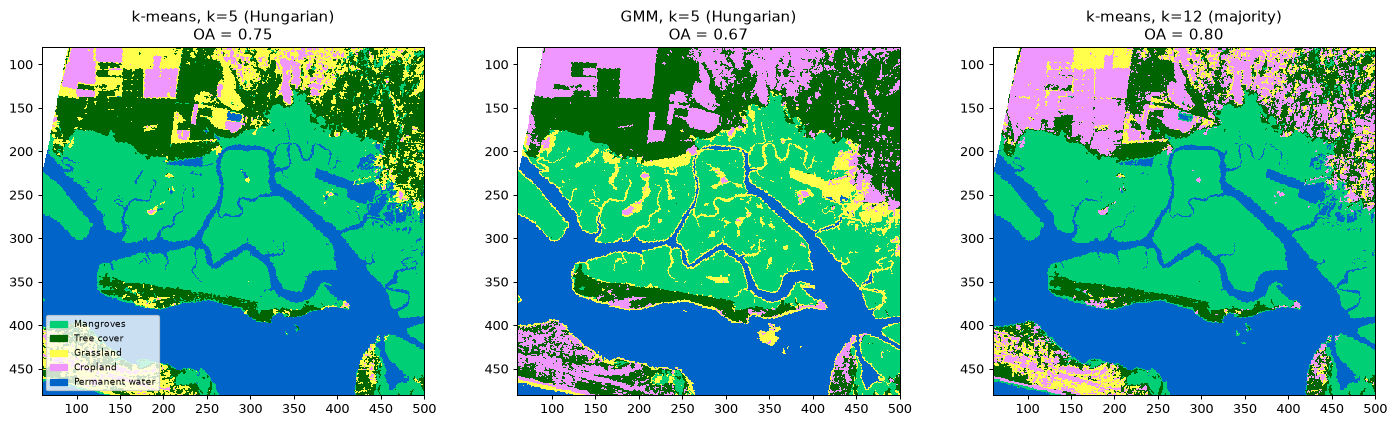

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (name, d) in zip(axes, unsup.items()):
    lab = d["mapping"][d["model"].predict(Z_all)].astype(float)
    lab[lab < 0] = np.nan
    ax.imshow(hu.pixels_to_image(lab, valid), cmap=cmap5, norm=norm5, interpolation="nearest", extent=ext)
    ax.set_title(f"{name}\nOA = {d['OA']:.2f}")
axes[0].legend(handles=legend5, fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()

Clusters follow the **largest spectral differences** in the image — for example water depth and turbidity, or
bright vs dark vegetation — which are not necessarily the differences in our legend. With five clusters, several
clusters are "spent" on variations within one class and some classes get no cluster at all. Allowing more clusters
than classes and merging them by majority usually helps, but unsupervised maps still need an analyst to interpret
them.

---
## 4. Supervised classification

Three classifiers that behave very differently:

| Classifier | Idea | Strengths / weaknesses for hyperspectral data |
|---|---|---|
| **LDA** (linear discriminant analysis) | Gaussian classes with a shared covariance → linear boundaries | Fast, a strong baseline; needs *shrinkage* of the covariance with 350 correlated bands |
| **Random Forest** (Breiman, 2001) | Many decision trees on bootstrap samples and random feature subsets; majority vote | Robust, little tuning, gives feature importances; axis-aligned splits use band correlation poorly |
| **SVM, RBF kernel** (Melgani & Bruzzone, 2004) | Maximum-margin boundary in a kernel space | Excellent with few samples in high dimensions; needs scaled features and tuning of C and γ |

In [8]:
models = {
    "LDA (shrinkage)": LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"),
    "Random Forest": RandomForestClassifier(n_estimators=300, n_jobs=4, random_state=0),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(C=10, gamma="scale")),
}
rows = []
for name, m in models.items():
    t0 = time.time(); m.fit(X_train, y_train); t_fit = time.time() - t0
    t0 = time.time(); p = m.predict(X_test); t_pred = time.time() - t0
    rows.append(dict(model=name, OA=accuracy_score(y_test, p), macro_F1=f1_score(y_test, p, average="macro"),
                     fit_s=t_fit, predict_s=t_pred))
pd.DataFrame(rows).set_index("model").round(3)

,OA,macro_F1,fit_s,predict_s
model,,,,
LDA (shrinkage),0.903,0.901,0.043,0.009
Random Forest,0.895,0.894,3.258,0.062
SVM (RBF),0.912,0.911,0.405,2.294


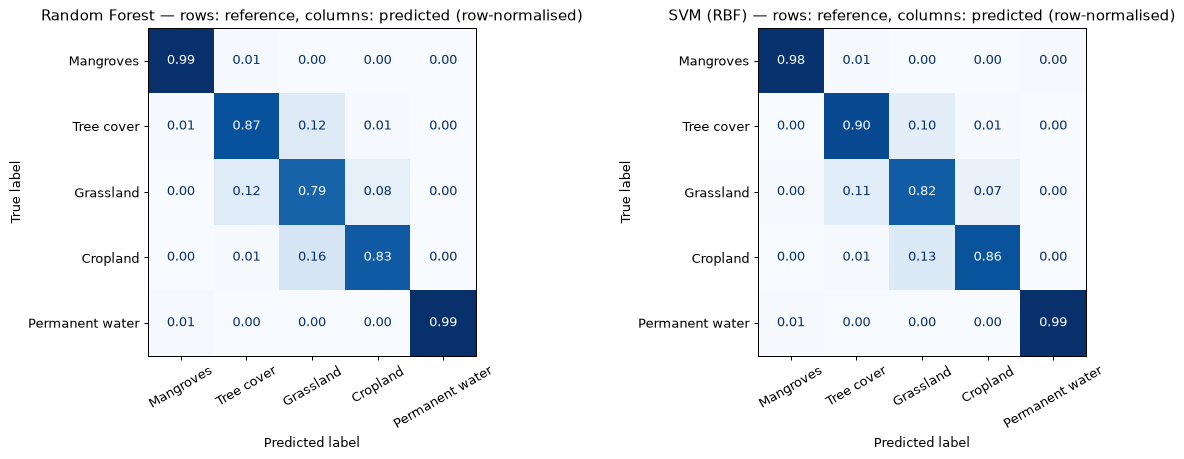

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, name in zip(axes, ["Random Forest", "SVM (RBF)"]):
    ConfusionMatrixDisplay.from_predictions(y_test, models[name].predict(X_test), display_labels=NAMES,
                                            normalize="true", values_format=".2f", cmap="Blues", ax=ax,
                                            colorbar=False, xticks_rotation=30)
    ax.set_title(f"{name} — rows: reference, columns: predicted (row-normalised)")
plt.tight_layout(); plt.show()

Read the confusion matrix row by row: the diagonal is the fraction of each reference class that was recognised
(*producer's accuracy* / recall); off-diagonal cells show which classes are confused. The typical confusions here are
between the vegetated classes: grassland is confused with both tree cover and cropland (open savanna with scattered
trees, fallow fields in the dry season). Mangroves and water are recognised almost perfectly. Grassland and cropland
are also the classes that are hardest to define consistently in the reference map.

### 4.1 Mapping the whole window

Random Forest: predicted 173721 pixels in 1 s


SVM (RBF): predicted 173721 pixels in 29 s


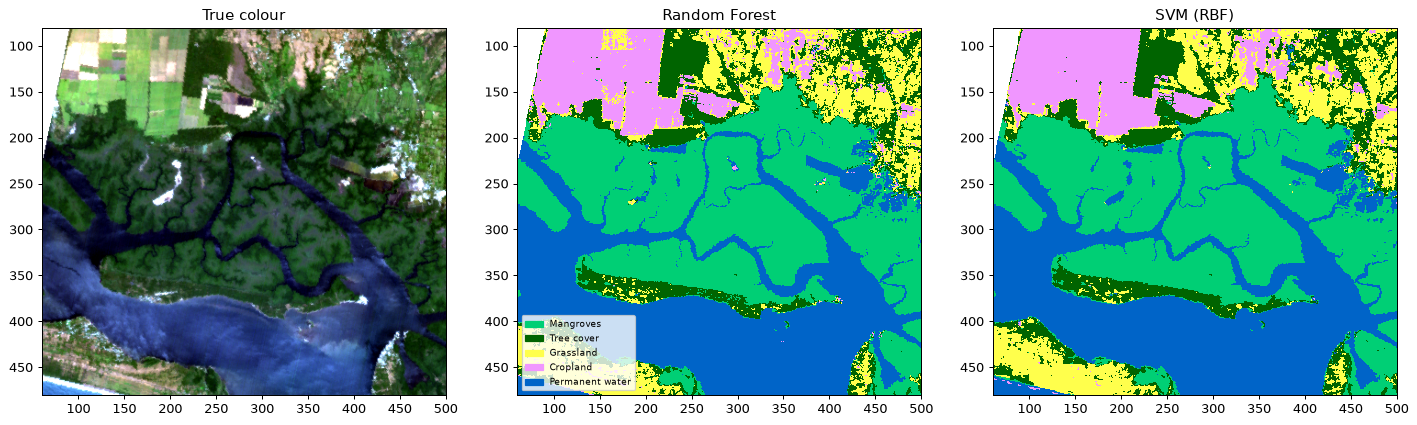

In [10]:
def predict_map(model, X, batch=40000):
    return np.concatenate([model.predict(X[i:i + batch]) for i in range(0, len(X), batch)])

maps = {}
for name in ["Random Forest", "SVM (RBF)"]:
    t0 = time.time()
    maps[name] = predict_map(models[name], X_all)
    print(f"{name}: predicted {len(X_all)} pixels in {time.time() - t0:.0f} s")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
axes[0].imshow(hu.rgb_from_cube(cube, wl), extent=ext); axes[0].set_title("True colour")
for ax, (name, pred) in zip(axes[1:], maps.items()):
    ax.imshow(hu.pixels_to_image(pred.astype(float), valid), cmap=cmap5, norm=norm5, interpolation="nearest",
              extent=ext)
    ax.set_title(name)
axes[1].legend(handles=legend5, fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()

### 4.2 Which wavelengths does the Random Forest use?

The *impurity-based importance* measures how much each band contributes to the splits of all trees. With strongly
correlated neighbouring bands the importance is shared among them, so look at **regions** rather than single bands.

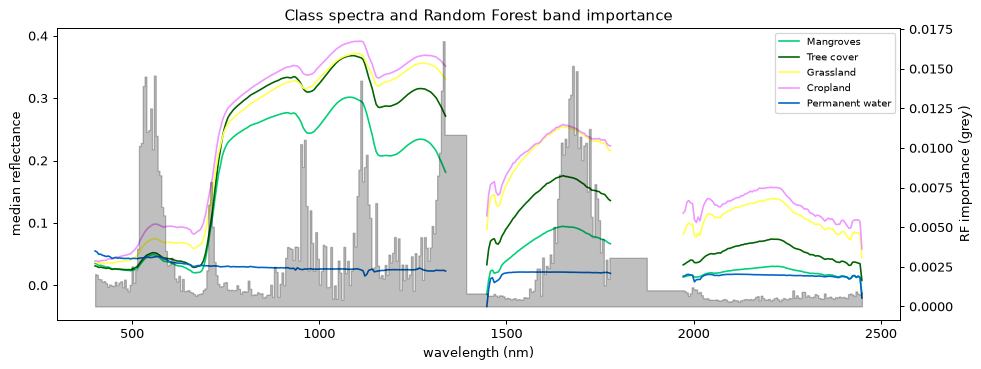

ten most important bands (nm): [ 531  536  561 1112 1327 1332 1668 1673 1678 1688]


In [11]:
imp = models["Random Forest"].feature_importances_
fig, ax1 = plt.subplots(figsize=(11, 4.2))
for i, (n, c) in enumerate(zip(NAMES, COLORS)):
    hu.plot_spectrum(ax1, wl, np.median(X_train[y_train == i], axis=0), color=c, lw=1.3, label=n)
ax1.set_xlabel("wavelength (nm)"); ax1.set_ylabel("median reflectance"); ax1.legend(fontsize=8, loc="upper right")
ax2 = ax1.twinx()
ax2.fill_between(wl, 0, imp, color="k", alpha=0.25, step="mid")
ax2.set_ylabel("RF importance (grey)")
ax1.set_title("Class spectra and Random Forest band importance")
plt.tight_layout(); plt.show()
top = np.argsort(imp)[::-1][:10]
print("ten most important bands (nm):", np.round(np.sort(wl[top])).astype(int))

## 5. Does the hyperspectral detail help?

A fair question for any hyperspectral project: *would Sentinel-2 have done the same job for free?* We train the same
classifiers on four feature sets computed from the same pixels:

1. **Full spectrum** — all good Tanager bands
2. **PCA-20** — the first 20 principal components (fitted on training pixels)
3. **Simulated Sentinel-2** — Tanager spectra convolved with Gaussian approximations of the 12 Sentinel-2 bands
   (`hu.resample_to_sensor`): the same pixels, the same date, only the spectral sampling changes
4. **Five indices** — NDVI, NDWI, NDRE, NDMI, MNDWI

In [12]:
s2_centers = [v[0] for v in hu.SENTINEL2_BANDS.values()]
s2_fwhm = [v[1] for v in hu.SENTINEL2_BANDS.values()]


def to_s2(X):
    return hu.resample_to_sensor(wl, X, s2_centers, s2_fwhm)


def to_indices(X):
    g = lambda nm: X[:, hu.band_index(wl, nm)]
    return np.c_[hu.nd(g(860), g(665)), hu.nd(g(560), g(860)), hu.nd(g(860), g(705)),
                 hu.nd(g(860), g(1650)), hu.nd(g(560), g(1650))]


pca20 = PCA(20, random_state=0).fit(X_train)
feature_sets = {
    "Full spectrum (%d)" % X_train.shape[1]: (X_train, X_test),
    "PCA-20": (pca20.transform(X_train), pca20.transform(X_test)),
    "Sentinel-2 simulated (12)": (to_s2(X_train), to_s2(X_test)),
    "Five indices (5)": (to_indices(X_train), to_indices(X_test)),
}
make = {
    "LDA": lambda: LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"),
    "RF": lambda: RandomForestClassifier(n_estimators=300, n_jobs=4, random_state=0),
    "SVM": lambda: make_pipeline(StandardScaler(), SVC(C=10, gamma="scale")),
}
rows, per_class = [], {}
for fs, (a, b) in feature_sets.items():
    for mn, mk in make.items():
        p = mk().fit(a, y_train).predict(b)
        rows.append(dict(features=fs, model=mn, OA=accuracy_score(y_test, p)))
        per_class[(fs, mn)] = f1_score(y_test, p, average=None)
comparison = pd.DataFrame(rows).pivot(index="features", columns="model", values="OA").loc[list(feature_sets)]
comparison.round(3)

model,LDA,RF,SVM
features,,,
Full spectrum (352),0.903,0.895,0.912
PCA-20,0.891,0.910,0.897
Sentinel-2 simulated (12),0.869,0.893,0.909
Five indices (5),0.792,0.839,0.845


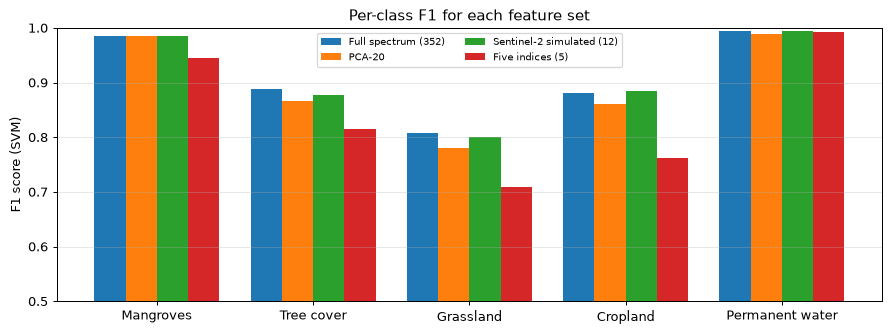

In [13]:
fig, ax = plt.subplots(figsize=(10, 3.8))
xpos = np.arange(len(NAMES))
for k, fs in enumerate(feature_sets):
    ax.bar(xpos + (k - 1.5) * 0.2, per_class[(fs, "SVM")], width=0.2, label=fs)
ax.set_xticks(xpos, NAMES); ax.set_ylim(0.5, 1); ax.set_ylabel("F1 score (SVM)")
ax.legend(fontsize=8, ncol=2); ax.grid(axis="y", alpha=0.3); ax.set_title("Per-class F1 for each feature set")
plt.tight_layout(); plt.show()

**Interpretation — be honest about what you find.** For these five *broad* land-cover classes, almost all of the
information is already captured by the 12 Sentinel-2-like bands: the full spectrum gives at most a small gain (it
helps LDA most, and PCA-20 even suits the Random Forest better than all bands), while a handful of indices loses
5–10 percentage points. Hyperspectral data pay off most when classes differ
in **narrow absorption features** (minerals, plant pigments and water content, species, materials — notebooks 13
and 14) rather than in overall brightness and greenness. A high-dimensional feature set also needs a classifier that
copes with correlated features (LDA with shrinkage and SVM do; PCA can help).

Keep in mind that the simulated Sentinel-2 data here have Tanager's 30 m pixels and noise; real Sentinel-2 has
10–20 m pixels, which can matter more than spectral detail for small patches.

---
## 6. Label noise: training and evaluating with imperfect labels

Our labels come from a **2021** 10 m map produced by another classifier, and our image is from **February 2025**
(dry season). Fields change crops, mangroves are cut or planted, and WorldCover itself has errors (its reported
global accuracy is about 77 %). Two experiments:

1. **Training purity** — train with pixels of at least purity 9, 7, 5 or 1 and always test on pure pixels.
2. **Test purity** — evaluate the *same* classifier against test pixels of decreasing purity.

In [14]:
rows = []
for min_p in (9, 7, 5, 1):
    r, c, y = sample_pixels(~is_test, 1500, min_purity=min_p)
    rf = RandomForestClassifier(n_estimators=300, n_jobs=4, random_state=0).fit(cube[:, r, c].T, y)
    rows.append(dict(training_min_purity=min_p, n_train=len(y),
                     OA_on_pure_test=accuracy_score(y_test, rf.predict(X_test))))
train_purity = pd.DataFrame(rows)

rf = models["Random Forest"]
rows = []
for p_level in (9, 8, 7, 6, 5):
    # balanced sample (≤ 1000 per class) of test pixels with exactly this purity
    r, c, y = sample_pixels(is_test & (purity == p_level), 1000, min_purity=p_level)
    rows.append(dict(test_purity=p_level, n_test=len(y),
                     OA=accuracy_score(y, rf.predict(cube[:, r, c].T))))
test_purity = pd.DataFrame(rows)
display(train_purity.round(3)); display(test_purity.round(3))

,training_min_purity,n_train,OA_on_pure_test
0,9,7500,0.893
1,7,7500,0.880
2,5,7500,0.893
3,1,7500,0.885


,test_purity,n_test,OA
0,9,5000,0.889
1,8,1513,0.658
2,7,1234,0.612
3,6,1901,0.542
4,5,1164,0.481


- Including less pure training pixels adds label noise (and mixed spectra), yet Random Forests are fairly robust to
  a moderate amount of it. More, noisier samples are not automatically worse — check it for your own data.
- The apparent accuracy **drops steeply** when the *test* pixels are less pure. Part of that is real (mixed pixels
  are harder), but part is the *reference* being wrong or ambiguous: a pixel with purity 5/9 is 44 % something else.
  Your accuracy can never be better than the quality of your reference data (notebook 21).

Where does the classifier disagree with WorldCover, even on pure pixels?

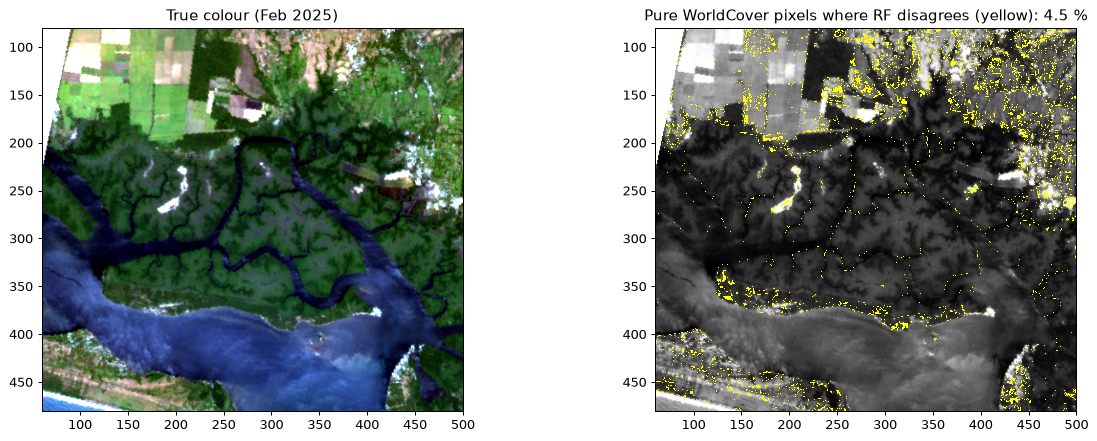

RF on Tanager 2025,Cropland,Grassland,Mangroves,Permanent water,Tree cover
WorldCover 2021,,,,,
Cropland,0,825,8,1,156
Grassland,1012,0,37,13,1213
Mangroves,20,74,0,349,735
Permanent water,23,13,412,0,12
Tree cover,129,1592,176,4,0


In [15]:
rf_img = hu.pixels_to_image(maps["Random Forest"].astype(float), valid)
ref_img = np.where((label_idx >= 0) & (purity == 9) & valid, label_idx, np.nan).astype(float)
disagree = np.where(np.isfinite(ref_img), (rf_img != ref_img).astype(float), np.nan)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(hu.rgb_from_cube(cube, wl), extent=ext); axes[0].set_title("True colour (Feb 2025)")
axes[1].imshow(hu.rgb_from_cube(cube, wl).mean(axis=2), cmap="gray", extent=ext)
axes[1].imshow(np.where(disagree == 1, 1.0, np.nan), cmap="autumn", vmin=0, vmax=1, extent=ext,
               interpolation="nearest")
axes[1].set_title(f"Pure WorldCover pixels where RF disagrees (yellow): {np.nanmean(disagree) * 100:.1f} %")
plt.tight_layout(); plt.show()

pairs = pd.crosstab(pd.Series(np.array(NAMES)[ref_img[disagree == 1].astype(int)], name="WorldCover 2021"),
                    pd.Series(np.array(NAMES)[rf_img[disagree == 1].astype(int)], name="RF on Tanager 2025"))
pairs

The table shows *which* labels disagree. Most disagreements are among **tree cover, grassland and cropland** —
classes whose boundaries are fuzzy (savanna with scattered trees, fallow or harvested fields in the dry season) and
which change between 2021 and 2025. Mangrove ↔ water disagreements sit along the **tidal channels**: channel
width, tide level at acquisition time and 10 m → 30 m aggregation all move that boundary. Mangrove → tree cover
occurs at the landward edge of the forest. Some of these are classifier errors, others are **label errors or real
change**. Before trusting an accuracy number, visit
some of these places in high-resolution imagery — this is exactly the *quality assurance* step of your project.

---
## 7. Comparison with a threshold classifier

Notebook 02 used fixed index thresholds (MNDWI > 0.1 → water, NDVI > 0.2 → vegetation, NDBI > 0 → built-up, else
bare). Thresholds are transparent and need no training data, but they can only separate classes that differ in one
index. We compare them with the Random Forest on the level they *can* address: **water vs vegetation**.

water/vegetation agreement with WorldCover on pure test pixels:  thresholds 99.6 %   RF 99.7 %
threshold classifier calls 0.1 % of these vegetation/water test pixels 'built-up' or 'bare'


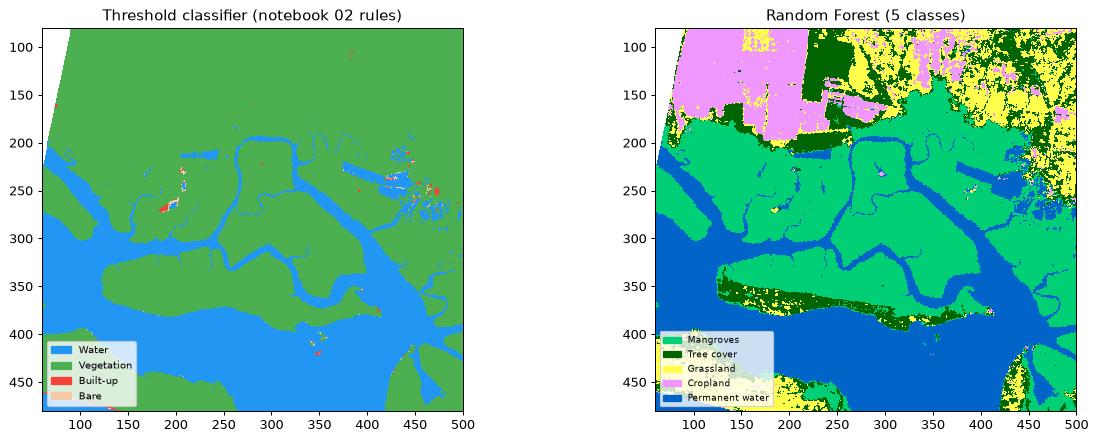

In [16]:
g = lambda nm: cube[hu.band_index(wl, nm)]
NDVI, MNDWI, NDBI = hu.nd(g(860), g(665)), hu.nd(g(560), g(1650)), hu.nd(g(1650), g(860))
thr = np.full(NDVI.shape, np.nan)
thr[NDBI > 0] = 2                     # built-up
thr[(NDBI <= 0) & (NDVI <= 0.2) & (MNDWI <= 0.1)] = 3   # bare
thr[NDVI > 0.2] = 1                   # vegetation
thr[MNDWI > 0.1] = 0                  # water (applied last, as in notebook 02)
thr[~valid] = np.nan

# collapse the 5 classes to water (0) / vegetation (1) for a like-for-like comparison
to_super = np.array([1, 1, 1, 1, 0])           # mangrove, tree, grass, crop → vegetation; water → water
y_super = to_super[y_test]
thr_pred = thr[te_r, te_c]
rf_pred = to_super[models["Random Forest"].predict(X_test)]
print(f"water/vegetation agreement with WorldCover on pure test pixels:"
      f"  thresholds {np.mean(thr_pred == y_super) * 100:.1f} %   RF {np.mean(rf_pred == y_super) * 100:.1f} %")
print(f"threshold classifier calls {np.mean(np.isin(thr_pred, [2, 3])) * 100:.1f} % of these vegetation/water "
      f"test pixels 'built-up' or 'bare'")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cmap4 = ListedColormap(["#2196F3", "#4CAF50", "#F44336", "#F5CBA7"])
axes[0].imshow(thr, cmap=cmap4, vmin=-0.5, vmax=3.5, interpolation="nearest", extent=ext)
axes[0].legend(handles=[Patch(color=c, label=l) for c, l in zip(cmap4.colors, ["Water", "Vegetation", "Built-up", "Bare"])],
               fontsize=8, loc="lower left")
axes[0].set_title("Threshold classifier (notebook 02 rules)")
axes[1].imshow(rf_img, cmap=cmap5, norm=norm5, interpolation="nearest", extent=ext)
axes[1].legend(handles=legend5, fontsize=7, loc="lower left"); axes[1].set_title("Random Forest (5 classes)")
plt.tight_layout(); plt.show()

Both approaches separate water from vegetation well, but the threshold map has only *one* vegetation class: it
cannot tell mangrove from cropland, which is the question a blue-carbon project actually needs answered. Fixed
thresholds also do not transfer between scenes and seasons. The supervised classifier needs labels — but it learns
whatever distinction the labels express.

---
## 8. Export the map as a Cloud-Optimised GeoTIFF

We store the Random Forest classes as WorldCover codes (so the same colour table applies) plus the forest's
**class probability** as a simple confidence layer. The window's geotransform places the map exactly on the Tanager
grid.

In [17]:
out_dir = hu.ensure_output_dir("15")
codes = np.zeros(valid.shape, dtype="uint8")                      # 0 = no data
codes[valid] = np.array(CLASSES, dtype="uint8")[maps["Random Forest"]]
proba = np.full(valid.shape, np.nan, dtype="float32")
proba[valid] = np.concatenate([models["Random Forest"].predict_proba(X_all[i:i + 40000]).max(axis=1)
                               for i in range(0, len(X_all), 40000)])

transform = scene.transform(W)
p1 = hu.save_geotiff(out_dir / f"{SCENE}_rf_classes.tif", codes, transform, scene.crs, nodata=0,
                     band_names=["worldcover_code"])
p2 = hu.save_geotiff(out_dir / f"{SCENE}_rf_confidence.tif", proba, transform, scene.crs,
                     band_names=["rf_max_probability"])

import rasterio
with rasterio.open(p1) as src:
    print(p1.name, src.crs, src.res, src.shape, "layout:", src.tags(ns="IMAGE_STRUCTURE").get("LAYOUT"))
print("mean confidence per predicted class:")
for i, n in enumerate(NAMES):
    print(f"  {n:18s} {np.nanmean(proba[codes == CLASSES[i]]):.2f}")

20250223_165546_32_4001_rf_classes.tif EPSG:32616 (30.0, 30.0) (400, 440) layout: COG
mean confidence per predicted class:
  Mangroves          0.97
  Tree cover         0.83
  Grassland          0.75
  Cropland           0.84
  Permanent water    0.98


The files open in QGIS, can be streamed from cloud storage, and can be overlaid on a web map. Low-confidence areas
(class boundaries, mixed pixels) are where you should look first during quality control.

---
## ✏️ Your turn

**1. Random vs spatial split.** Draw training and test pixels *at random* from the whole window (ignore the blocks)
and retrain the Random Forest. Is the accuracy higher? Why is that number misleading?

<details><summary>Hint</summary>Use <code>sample_pixels(np.ones_like(is_test), 4500)</code> and
<code>sklearn.model_selection.train_test_split</code>. Notebook 21 shows how to do spatial cross-validation properly.</details>
<details><summary>Solution</summary>

```python
from sklearn.model_selection import train_test_split
r, c, y = sample_pixels(np.ones_like(is_test), 4500)
Xa, Xb, ya, yb = train_test_split(cube[:, r, c].T, y, test_size=0.4, random_state=0, stratify=y)
rf_rand = RandomForestClassifier(300, n_jobs=4, random_state=0).fit(Xa, ya)
print("random split OA:", accuracy_score(yb, rf_rand.predict(Xb)))
```
The random-split test pixels have neighbours in the training set, so the classifier is partly tested on
near-duplicates. The gap between the two numbers is an estimate of the optimism.
</details>

**2. Tune the SVM.** Use `GridSearchCV` with `C ∈ {1, 10, 100}` and `gamma ∈ {"scale", 0.01, 0.001}` on the training
pixels. Use `GroupKFold` with the block IDs as groups so the tuning is spatially honest too.

<details><summary>Solution</summary>

```python
from sklearn.model_selection import GridSearchCV, GroupKFold
groups = block_id[tr_r, tr_c]
grid = GridSearchCV(make_pipeline(StandardScaler(), SVC()),
                    {"svc__C": [1, 10, 100], "svc__gamma": ["scale", 0.01, 0.001]},
                    cv=GroupKFold(5), n_jobs=4)
grid.fit(X_train, y_train, groups=groups)
print(grid.best_params_, grid.best_score_, accuracy_score(y_test, grid.predict(X_test)))
```
</details>

**3. Fewer training samples.** Repeat the feature-set comparison with only 50 training pixels per class. Does the
full spectrum still help, or does the Hughes phenomenon appear? Which classifier suffers most?

**4. Add a class.** Merge built-up, bare and herbaceous wetland into an "other" class (use purity ≥ 6 to get enough
samples) and retrain. What happens to the accuracy of the other classes?

**5. SAM as a classifier.** Use the class median spectra of the training pixels as references and classify the test
pixels with the minimum spectral angle (notebook 14). How does it compare with LDA, RF and SVM?

<details><summary>Solution</summary>

```python
refs = np.array([np.median(X_train[y_train == i], axis=0) for i in range(5)])
ang = np.stack([hu.spectral_angle(X_test, r) for r in refs], axis=1)
print("SAM OA:", accuracy_score(y_test, ang.argmin(axis=1)))
```
</details>

---
## Key takeaways
- **Labels are the bottleneck.** Reference maps such as WorldCover are a quick start, but they are older, coarser
  and imperfect; filter by purity and check disagreements visually.
- **Always split spatially.** Random pixel splits overestimate accuracy because of spatial autocorrelation.
- **Unsupervised clustering** finds the dominant spectral structure, which rarely matches your legend one-to-one.
- **SVM and LDA with shrinkage** cope well with hundreds of correlated bands; Random Forests are robust and explain
  which wavelengths matter.
- **Quantify the hyperspectral benefit** against simulated multispectral data. For broad classes it may be modest;
  for material-specific questions it is where hyperspectral shines.
- Export maps as **COGs** together with a **confidence** layer.

**For your project:** decide early where your labels come from (existing maps, field data, visual interpretation of
VHR imagery), how many you need per class, and how you will split them spatially. Then validate properly in
notebook 21.

**References:** Hughes (1968) *IEEE Trans. Inf. Theory* 14; Breiman (2001) *Machine Learning* 45; Melgani &
Bruzzone (2004) *IEEE TGRS* 42; Camps-Valls & Bruzzone (2005) *IEEE TGRS* 43; Zanaga et al. (2022) *ESA WorldCover
10 m 2021 v200*; Ploton et al. (2020) *Nature Communications* 11 (spatial validation).

> 📖 Data: Tanager — CC-BY-4.0 © Planet Labs PBC · ESA WorldCover 2021 v200 — CC-BY 4.0